In [2]:
# 0. setup
!pip install -q ultralytics
import os, subprocess, sys, glob, pickle, time
DS   = '/kaggle/input/datasets/nonitgupta/crickshot10k'
MD   = '/kaggle/input/datasets/nonitgupta/player-type-detection'
BAT  = f'{MD}/Bat_Detection_Model.pt'
SEG  = f'{MD}/Striker_Bat_Segmentation_Model.pt'
POSE = '/kaggle/working/yolo11m-pose.pt'
for p in (DS, BAT, SEG): print(os.path.exists(p), p)

True /kaggle/input/datasets/nonitgupta/crickshot10k
True /kaggle/input/datasets/nonitgupta/player-type-detection/Bat_Detection_Model.pt
True /kaggle/input/datasets/nonitgupta/player-type-detection/Striker_Bat_Segmentation_Model.pt


In [3]:
# 1. pre-download the pose weights to an absolute path (so both GPU workers find them)
if not os.path.exists(POSE):
    from ultralytics import YOLO
    import shutil
    YOLO('yolo11m-pose.pt')                      # downloads into the current dir
    for cand in ('yolo11m-pose.pt', os.path.expanduser('~/yolo11m-pose.pt')):
        if os.path.exists(cand) and os.path.abspath(cand) != POSE:
            shutil.copy(cand, POSE); break
print(os.path.exists(POSE), os.path.getsize(POSE) / 1e6, 'MB')

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
True 42.459307 MB


In [4]:
%%writefile /kaggle/working/cricpre.py
"""
Stage 1 preprocessing for CricShot10k (pose-guided CricShotNet variant).

Per clip:
  1. Read all frames of the raw clip (~24 frames, 896x540).
  2. Multi-person pose (YOLO11-pose) + bat detector on every frame.
  3. Pick the striker with a Viterbi track over the whole clip (bat proximity + size/centrality prior
     + temporal consistency).  This replaces the unavailable 8-class player-type detector.
  4. Optional pose refinement on an aspect-preserving striker crop (better keypoints in wide shots).
  5. Crop (striker box U bat box, paper-style padding) -> 224x224 -> segmentation overlay (paper's seg model).
  6. Cache everything per chunk of clips: JPEG overlays, keypoints (raw-frame pixels), boxes, flags.

Clip order is a fixed random shuffle, so any prefix of finished chunks is a random (roughly stratified) subset.
Chunks are atomic and resumable.
"""
import os, re, sys, time, pickle, random, argparse
import numpy as np
import cv2

N_KP = 17
MAX_FRAMES = 64
JPEG_Q = 92
SKELETON = [(5, 7), (7, 9), (6, 8), (8, 10), (5, 6), (5, 11), (6, 12), (11, 12), (11, 13), (13, 15), (12, 14), (14, 16)]


# ----------------------------------------------------------------------------- utilities
def _np(x):
    if hasattr(x, "cpu"):
        x = x.cpu()
    if hasattr(x, "numpy"):
        x = x.numpy()
    return np.asarray(x)


def iou(a, b):
    ix1, iy1 = max(a[0], b[0]), max(a[1], b[1])
    ix2, iy2 = min(a[2], b[2]), min(a[3], b[3])
    inter = max(0.0, ix2 - ix1) * max(0.0, iy2 - iy1)
    ua = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return float(inter / ua) if ua > 0 else 0.0


def list_clips(ds):
    """All clips under ds, deterministic order = fixed random shuffle (same in every shard)."""
    paths = []
    for dp, _, fs in os.walk(ds):
        for f in fs:
            if f.lower().endswith((".avi", ".mp4", ".mov")):
                paths.append(os.path.join(dp, f))
    paths.sort()
    rows = []
    for p in paths:
        m = re.search(r"vid(\d+)_(\d+)", os.path.basename(p))
        rows.append(dict(path=p, cls=os.path.basename(os.path.dirname(p)),
                         match=int(m.group(1)) if m else -1, clip=int(m.group(2)) if m else -1))
    random.Random(0).shuffle(rows)
    return rows


def read_frames(path, max_frames=MAX_FRAMES):
    cap = cv2.VideoCapture(path)
    fr = []
    while len(fr) < max_frames:
        ok, f = cap.read()
        if not ok:
            break
        fr.append(f)
    cap.release()
    return fr


# ----------------------------------------------------------------------------- parsing model outputs
def parse_pose(res):
    if res.boxes is None or len(res.boxes) == 0 or res.keypoints is None:
        return np.zeros((0, 4), np.float32), np.zeros((0, N_KP, 2), np.float32), np.zeros((0, N_KP), np.float32)
    b = _np(res.boxes.xyxy).astype(np.float32)
    kp = _np(res.keypoints.xy).astype(np.float32)
    kc = _np(res.keypoints.conf).astype(np.float32) if res.keypoints.conf is not None else np.ones(kp.shape[:2], np.float32)
    return b, kp, kc


def parse_bat(res):
    if res.boxes is None or len(res.boxes) == 0:
        return None
    b = _np(res.boxes.xyxy).astype(np.float32)
    c = _np(res.boxes.conf).astype(np.float32)
    return b[int(np.argmax(c))]


# ----------------------------------------------------------------------------- striker selection
def person_scores(boxes, kp, kc, bat, W, H):
    """Unary score per person: size/centrality prior + keypoint visibility + wrist-to-bat proximity."""
    k = len(boxes)
    if k == 0:
        return np.zeros(0, np.float32)
    h = np.maximum(boxes[:, 3] - boxes[:, 1], 1.0)
    w = np.maximum(boxes[:, 2] - boxes[:, 0], 1.0)
    area = (w * h) / float(W * H)
    cx = (boxes[:, 0] + boxes[:, 2]) / 2
    prior = np.sqrt(area) * (1 - 0.5 * np.abs(cx - W / 2) / (W / 2))
    vis = (kc > 0.5).mean(1)
    s = 2.0 * prior + 0.5 * vis
    if bat is not None:
        bx1, by1, bx2, by2 = [float(v) for v in bat]
        barea = max((bx2 - bx1) * (by2 - by1), 1.0)
        for i in range(k):
            d = 1e9
            for j in (9, 10):  # wrists
                if kc[i, j] > 0.3:
                    x, y = kp[i, j]
                    d = min(d, float(np.hypot(max(bx1 - x, 0, x - bx2), max(by1 - y, 0, y - by2))))
            bs = max(0.0, 1.0 - (d / h[i]) / 0.35) if d < 1e8 else 0.0
            ix = max(0.0, min(bx2, boxes[i, 2]) - max(bx1, boxes[i, 0]))
            iy = max(0.0, min(by2, boxes[i, 3]) - max(by1, boxes[i, 1]))
            bs = max(bs, 0.5 * (ix * iy) / barea)  # bat inside the person's box even if wrists are occluded
            s[i] += 3.0 * bs
    return s


def _trans_cost(a, b):
    ha, hb = a[3] - a[1], b[3] - b[1]
    d = np.hypot((a[0] + a[2]) / 2 - (b[0] + b[2]) / 2, (a[1] + a[3]) / 2 - (b[1] + b[3]) / 2)
    d = d / max(0.5 * (ha + hb), 1.0)
    return 1.5 * (1 - iou(a, b)) + min(1.0, float(d))


def track_striker(boxes_l, scores_l, person_bias=0.4, p2n=0.6, n2n=0.1):
    """Viterbi over frames. State per frame = one of its persons, or 'none'. Returns index per frame (-1 = none)."""
    T = len(boxes_l)
    best, back = [], []
    for t in range(T):
        k = len(boxes_l[t])
        sc = np.concatenate([np.asarray(scores_l[t], np.float64) - person_bias, [0.0]])
        if t == 0:
            best.append(sc)
            back.append(np.full(k + 1, -1))
            continue
        kp_ = len(boxes_l[t - 1])
        prev = best[-1]
        cur = np.empty(k + 1)
        bk = np.empty(k + 1, dtype=int)
        for s in range(k + 1):
            cand = np.empty(kp_ + 1)
            for s2 in range(kp_ + 1):
                if s < k and s2 < kp_:
                    c = _trans_cost(boxes_l[t - 1][s2], boxes_l[t][s])
                elif s == k and s2 == kp_:
                    c = n2n
                else:
                    c = p2n
                cand[s2] = prev[s2] - c
            bk[s] = int(np.argmax(cand))
            cur[s] = cand[bk[s]] + sc[s]
        best.append(cur)
        back.append(bk)
    s = int(np.argmax(best[-1]))
    out = [-1] * T
    for t in range(T - 1, -1, -1):
        k = len(boxes_l[t])
        out[t] = s if s < k else -1
        s = int(back[t][s])
    return out


# ----------------------------------------------------------------------------- cropping
def make_crop_box(sbox, bat, W, H):
    """Paper-style crop: striker box U bat box (only if the bat is plausibly in the striker's hands), +10% x pad, +5% y pad."""
    x1, y1, x2, y2 = [float(v) for v in sbox]
    if bat is not None:
        w, h = x2 - x1, y2 - y1
        bcx, bcy = (bat[0] + bat[2]) / 2, (bat[1] + bat[3]) / 2
        if x1 - 0.4 * w <= bcx <= x2 + 0.4 * w and y1 - 0.4 * h <= bcy <= y2 + 0.4 * h:
            x1, y1, x2, y2 = min(x1, bat[0]), min(y1, bat[1]), max(x2, bat[2]), max(y2, bat[3])
    w, h = x2 - x1, y2 - y1
    x1 -= 0.10 * w
    x2 += 0.10 * w
    y1 -= 0.05 * h
    y2 += 0.05 * h
    x1, y1 = max(0, int(x1)), max(0, int(y1))
    x2, y2 = min(W, int(np.ceil(x2))), min(H, int(np.ceil(y2)))
    if x2 - x1 < 8 or y2 - y1 < 8:
        return None
    return (x1, y1, x2, y2)


def _jpg(im):
    return cv2.imencode(".jpg", im, [cv2.IMWRITE_JPEG_QUALITY, JPEG_Q])[1].tobytes()


# ----------------------------------------------------------------------------- one clip
def process_clip(frames, M, refine=True, save_raw=False):
    N = len(frames)
    H, W = frames[0].shape[:2]
    pres = M["pose"](frames, imgsz=640, half=True, verbose=False)
    bres = M["bat"](frames, max_det=1, half=True, verbose=False)
    dets = [parse_pose(r) for r in pres]
    bats = [parse_bat(r) for r in bres]

    scores_l = [person_scores(d[0], d[1], d[2], bats[t], W, H) for t, d in enumerate(dets)]
    sel = track_striker([d[0] for d in dets], scores_l)
    valid = np.array([s >= 0 for s in sel])
    if not valid.any():
        return dict(ok=False, reason="no_striker", n=N, W=W, H=H)

    sbox = np.zeros((N, 4), np.float32)
    kp = np.zeros((N, N_KP, 2), np.float32)
    kc = np.zeros((N, N_KP), np.float32)
    for t, s in enumerate(sel):
        if s >= 0:
            sbox[t], kp[t], kc[t] = dets[t][0][s], dets[t][1][s], dets[t][2][s]
    vi = np.where(valid)[0]
    for t in range(N):  # frames without the striker keep the nearest valid box (flagged by `valid`)
        if not valid[t]:
            sbox[t] = sbox[vi[np.argmin(np.abs(vi - t))]]

    n_refined = 0
    if refine:  # re-run pose on an aspect-preserving, upscaled crop around the striker
        crops, meta = [], []
        for t in vi:
            b = sbox[t]
            w, h = b[2] - b[0], b[3] - b[1]
            x1, y1 = int(max(0, b[0] - 0.2 * w)), int(max(0, b[1] - 0.2 * h))
            x2, y2 = int(min(W, b[2] + 0.2 * w)), int(min(H, b[3] + 0.2 * h))
            if x2 - x1 >= 8 and y2 - y1 >= 8:
                crops.append(frames[t][y1:y2, x1:x2])
                meta.append((t, x1, y1))
        if crops:
            rres = M["pose"](crops, imgsz=384, half=True, verbose=False)
            for (t, x1, y1), r in zip(meta, rres):
                bb, kk, cc = parse_pose(r)
                if len(bb) == 0:
                    continue
                ob = sbox[t] - np.array([x1, y1, x1, y1], np.float32)
                ious = [iou(b_, ob) for b_ in bb]
                j = int(np.argmax(ious))
                if ious[j] > 0.3:
                    kp[t] = kk[j] + np.array([x1, y1], np.float32)
                    kc[t] = cc[j]
                    n_refined += 1

    cbox = np.zeros((N, 4), np.int32)
    bat_arr = np.full((N, 4), -1, np.float32)
    crops224 = []
    for t in range(N):
        if bats[t] is not None:
            bat_arr[t] = bats[t]
        cb = make_crop_box(sbox[t], bats[t], W, H) or (0, 0, W, H)
        cbox[t] = cb
        crops224.append(cv2.resize(frames[t][cb[1]:cb[3], cb[0]:cb[2]], (224, 224)))

    sres = M["seg"](crops224, imgsz=256, max_det=2, half=True, verbose=False)
    seg = [np.ascontiguousarray(r.plot(boxes=False, probs=False, labels=False)) for r in sres]
    nmask = np.array([0 if r.masks is None else len(r.masks) for r in sres], np.int8)

    rec = dict(ok=True, n=N, W=W, H=H, jpg_seg=[_jpg(im) for im in seg], kp=kp, kc=kc, valid=valid,
               sbox=sbox, cbox=cbox, bat=bat_arr, nmask=nmask, n_refined=n_refined)
    if save_raw:
        rec["jpg_raw"] = [_jpg(im) for im in crops224]
    return rec


# ----------------------------------------------------------------------------- shard runner
def run_shard(rows, M, out, shard=0, nshards=1, chunk=100, refine=True, save_raw=False, limit=0,
              log=print, max_consec_fail=15):
    os.makedirs(out, exist_ok=True)
    if limit:
        rows = rows[:limit]
    nchunks = (len(rows) + chunk - 1) // chunk
    mine = [c for c in range(nchunks) if c % nshards == shard]
    t0, done, consec = time.time(), 0, 0
    for c in mine:
        fn = os.path.join(out, f"chunk_{c:04d}.pkl")
        if os.path.exists(fn):
            log(f"skip existing {os.path.basename(fn)}")
            continue
        recs = []
        for r in rows[c * chunk:(c + 1) * chunk]:
            try:
                fr = read_frames(r["path"])
                rec = dict(ok=False, reason="short", n=len(fr)) if len(fr) < 5 else process_clip(fr, M, refine, save_raw)
            except Exception as e:  # keep going; a systematic bug is caught below
                rec = dict(ok=False, reason="exc:" + repr(e)[:200])
            consec = consec + 1 if str(rec.get("reason", "")).startswith("exc:") else 0
            if consec >= max_consec_fail:
                raise RuntimeError(f"{consec} consecutive clip failures, last: {rec['reason']}")
            rec.update(r)
            recs.append(rec)
            done += 1
        tmp = fn + ".tmp"
        with open(tmp, "wb") as f:
            pickle.dump(recs, f, protocol=4)
        os.replace(tmp, fn)
        el = time.time() - t0
        log(f"shard {shard} chunk {c} done | {done} clips | {el / done:.2f}s/clip | ok {sum(bool(x['ok']) for x in recs)}/{len(recs)}")
    return done


# ----------------------------------------------------------------------------- QA montage
def montage(rec, n_show=8, size=224):
    """Grid image: top row = segmentation overlay, bottom row = overlay + keypoints (crop coordinates)."""
    n = rec["n"]
    idx = np.linspace(0, n - 1, min(n_show, n)).round().astype(int)
    top, bot = [], []
    for t in idx:
        im = cv2.imdecode(np.frombuffer(rec["jpg_seg"][t], np.uint8), cv2.IMREAD_COLOR)
        top.append(im.copy())
        x1, y1, x2, y2 = rec["cbox"][t]
        sx, sy = size / max(x2 - x1, 1), size / max(y2 - y1, 1)
        pts = [((x - x1) * sx, (y - y1) * sy, c) for (x, y), c in zip(rec["kp"][t], rec["kc"][t])]
        for a, b in SKELETON:
            if pts[a][2] > 0.3 and pts[b][2] > 0.3:
                cv2.line(im, (int(pts[a][0]), int(pts[a][1])), (int(pts[b][0]), int(pts[b][1])), (0, 255, 255), 2)
        for x, y, c in pts:
            if c > 0.3:
                cv2.circle(im, (int(x), int(y)), 3, (0, 0, 255), -1)
        cv2.putText(im, f"{t}{'' if rec['valid'][t] else ' (no striker)'}", (4, 16), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 255), 1)
        bot.append(im)
    return np.vstack([np.hstack(top), np.hstack(bot)])


# ----------------------------------------------------------------------------- cache summary
def summarize(out):
    """Per-class QA of a cache directory, read chunk by chunk (never holds the whole cache in RAM)."""
    import glob, collections
    per = collections.defaultdict(lambda: [0, 0, 0.0, 0.0])  # n, ok, sum valid-frac, sum bat-frac
    fails = collections.Counter()
    size, nfiles = 0, 0
    for f in sorted(glob.glob(os.path.join(out, "chunk_*.pkl"))):
        size += os.path.getsize(f)
        nfiles += 1
        for r in pickle.load(open(f, "rb")):
            p = per[r["cls"]]
            p[0] += 1
            if r["ok"]:
                p[1] += 1
                p[2] += float(r["valid"].mean())
                p[3] += float((r["bat"][:, 0] >= 0).mean())
            else:
                fails[str(r.get("reason"))[:60]] += 1
    tot = sum(p[0] for p in per.values())
    ok = sum(p[1] for p in per.values())
    print(f"{nfiles} chunks | {tot} clips cached | ok {ok} ({100 * ok / max(tot, 1):.1f}%) | {size / 1e9:.2f} GB")
    print(f"{'class':18s} {'n':>5s} {'ok%':>6s} {'striker-frames%':>16s} {'bat-frames%':>12s}")
    for c in sorted(per):
        n, k, v, b = per[c]
        print(f"{c:18s} {n:5d} {100 * k / max(n, 1):6.1f} {100 * v / max(k, 1):16.1f} {100 * b / max(k, 1):12.1f}")
    if fails:
        print("failure reasons:", dict(fails))
    return per


# ----------------------------------------------------------------------------- main
def load_models(pose, bat, seg):
    from ultralytics import YOLO
    M = dict(pose=YOLO(pose), bat=YOLO(bat), seg=YOLO(seg))
    dummy = np.zeros((540, 896, 3), np.uint8)
    M["pose"]([dummy], imgsz=640, half=True, verbose=False)
    M["bat"]([dummy], max_det=1, half=True, verbose=False)
    M["seg"]([np.zeros((224, 224, 3), np.uint8)], imgsz=256, max_det=2, half=True, verbose=False)
    return M


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--ds", required=True)
    ap.add_argument("--out", required=True)
    ap.add_argument("--pose", required=True)
    ap.add_argument("--bat", required=True)
    ap.add_argument("--seg", required=True)
    ap.add_argument("--shard", type=int, default=0)
    ap.add_argument("--nshards", type=int, default=1)
    ap.add_argument("--gpu", type=int, default=0)
    ap.add_argument("--chunk", type=int, default=100)
    ap.add_argument("--limit", type=int, default=0)
    ap.add_argument("--refine", type=int, default=1)
    ap.add_argument("--save_raw", type=int, default=0)
    a = ap.parse_args()
    os.environ["CUDA_VISIBLE_DEVICES"] = str(a.gpu)  # before torch is imported
    log = lambda s: print(f"[{time.strftime('%H:%M:%S')}] {s}", flush=True)
    rows = list_clips(a.ds)
    log(f"{len(rows)} clips | shard {a.shard}/{a.nshards} | gpu {a.gpu}")
    M = load_models(a.pose, a.bat, a.seg)
    n = run_shard(rows, M, a.out, a.shard, a.nshards, a.chunk, bool(a.refine), bool(a.save_raw), a.limit, log)
    log(f"finished, {n} clips processed in this run")


if __name__ == "__main__":
    main()

Writing /kaggle/working/cricpre.py


tize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'qua

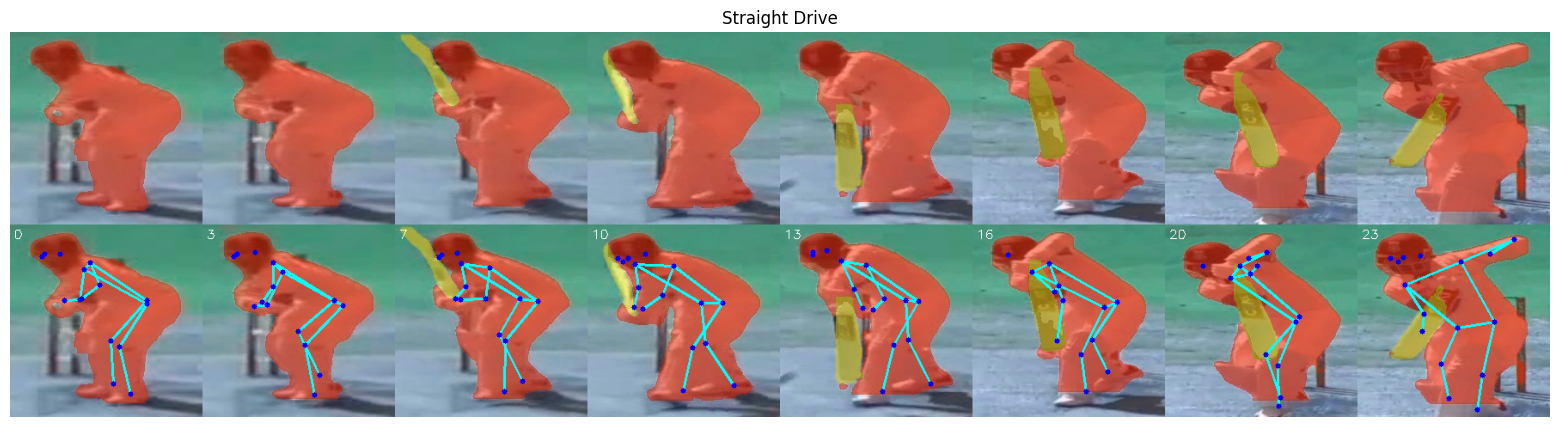

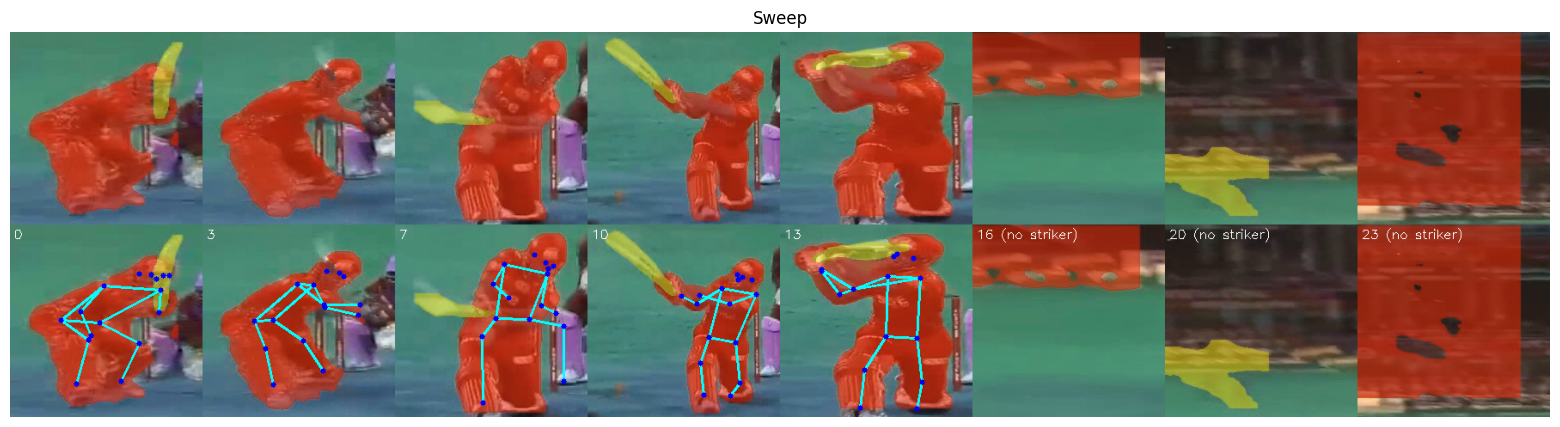

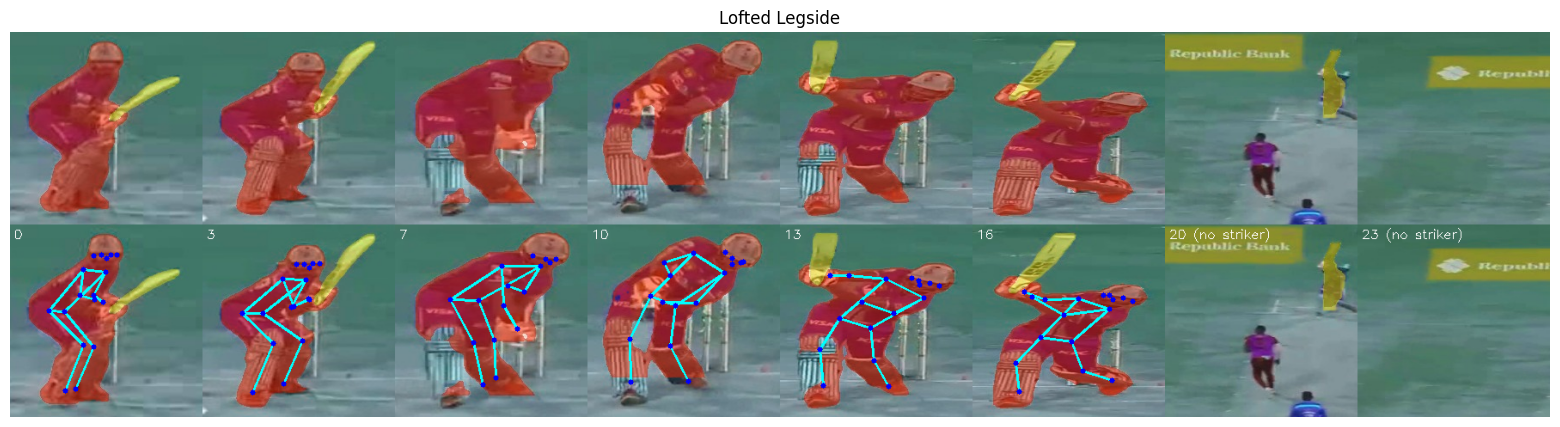

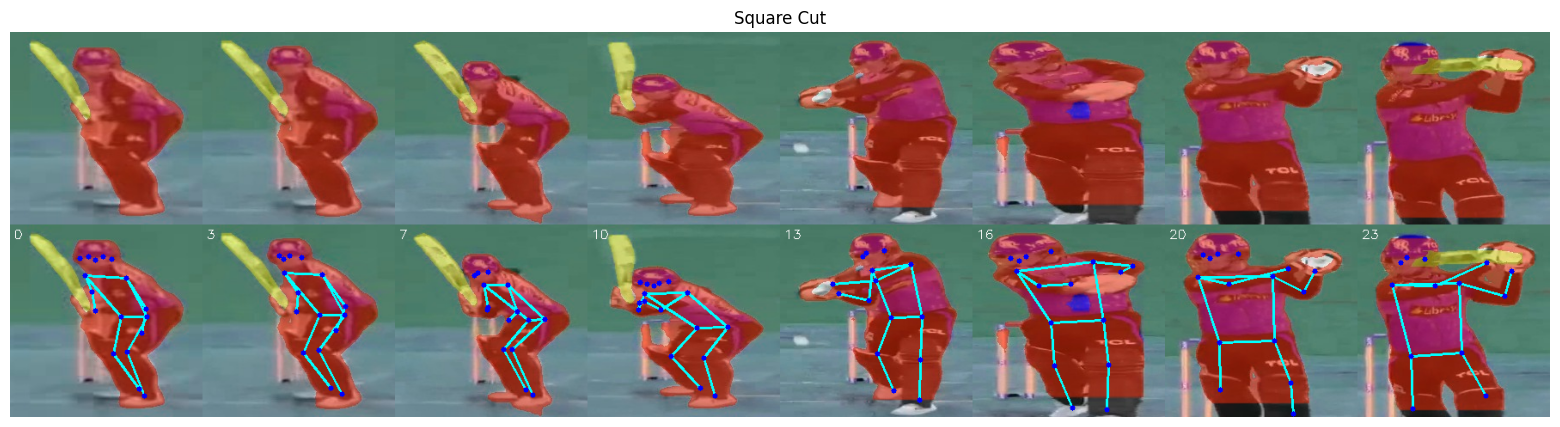

In [5]:
# 3. TEST RUN: 24 random clips on one GPU. Check ok-rate, striker-frame %, bat %, seconds/clip and the montages.
import numpy as np, matplotlib.pyplot as plt
sys.path.insert(0, '/kaggle/working')
TEST = '/kaggle/working/cache_test'
!rm -rf {TEST}
t0 = time.time()
r = subprocess.run([sys.executable, '/kaggle/working/cricpre.py', '--ds', DS, '--out', TEST, '--pose', POSE,
                    '--bat', BAT, '--seg', SEG, '--limit', '24', '--chunk', '12', '--gpu', '0'],
                   capture_output=True, text=True)
print(r.stdout[-2500:]); print(r.stderr[-2500:])
import cricpre as cp
per = cp.summarize(TEST)
recs = [x for f in sorted(glob.glob(TEST + '/chunk_*.pkl')) for x in pickle.load(open(f, 'rb'))]
print('wall time incl. model load:', round(time.time() - t0), 's for', len(recs), 'clips')
for rec in recs[:6]:
    print(rec['cls'], os.path.basename(str(rec.get('path'))), 'ok' if rec['ok'] else rec.get('reason'), 'frames', rec.get('n'),
          'striker%', round(float(rec['valid'].mean()) * 100) if rec['ok'] else '-',
          'refined', rec.get('n_refined'))
for rec in [x for x in recs if x['ok']][:4]:
    plt.figure(figsize=(20, 5)); plt.imshow(cp.montage(rec)); plt.axis('off'); plt.title(f"{rec['cls']}"); plt.show()

In [6]:
# 4. FULL RUN, two GPUs in parallel. This cell blocks until both workers finish (needed for Commit runs).
OUT = '/kaggle/working/cache'
os.makedirs(OUT, exist_ok=True)
procs = []
for g in (0, 1):
    lf = open(f'/kaggle/working/log_gpu{g}.txt', 'a')
    procs.append(subprocess.Popen([sys.executable, '/kaggle/working/cricpre.py', '--ds', DS, '--out', OUT, '--pose', POSE,
        '--bat', BAT, '--seg', SEG, '--shard', str(g), '--nshards', '2', '--gpu', str(g), '--chunk', '100'],
        stdout=lf, stderr=subprocess.STDOUT))
t0 = time.time()
while any(p.poll() is None for p in procs):
    time.sleep(300)
    n = len(glob.glob(OUT + '/chunk_*.pkl'))
    print(f'{(time.time()-t0)/60:6.1f} min | {n}/101 chunks done', flush=True)
print('exit codes', [p.returncode for p in procs])
for g in (0, 1): print(open(f'/kaggle/working/log_gpu{g}.txt').read()[-600:])

   5.0 min | 5/101 chunks done
  10.0 min | 11/101 chunks done
  15.0 min | 17/101 chunks done
  20.0 min | 23/101 chunks done
  25.0 min | 29/101 chunks done
  30.0 min | 36/101 chunks done
  35.0 min | 42/101 chunks done
  40.0 min | 48/101 chunks done
  45.0 min | 54/101 chunks done
  50.0 min | 60/101 chunks done
  55.0 min | 66/101 chunks done
  60.0 min | 73/101 chunks done
  65.0 min | 79/101 chunks done
  70.0 min | 85/101 chunks done
  75.0 min | 91/101 chunks done
  80.0 min | 97/101 chunks done
  85.0 min | 100/101 chunks done
  90.0 min | 101/101 chunks done
exit codes [0, 0]
'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is 

In [7]:
# 5. summary of the finished cache
import cricpre as cp
_ = cp.summarize('/kaggle/working/cache')

101 chunks | 10091 clips cached | ok 10091 (100.0%) | 3.22 GB
class                  n    ok%  striker-frames%  bat-frames%
Cover Drive          772  100.0             93.9         76.6
Defensive            605  100.0             98.2         68.7
Down The Wicket      890  100.0             98.0         78.3
Flick                933  100.0             95.7         72.6
Hook                 534  100.0             89.8         76.7
Late Cut             306  100.0             97.0         77.3
Lofted Legside      1123  100.0             94.5         77.0
Lofted Offside      1023  100.0             93.5         75.1
Pull                 745  100.0             95.9         81.5
Reverse Sweep        252  100.0             97.2         66.4
Scoop                279  100.0             95.1         73.5
Square Cut          1023  100.0             94.8         78.9
Straight Drive       423  100.0             95.6         69.1
Sweep                908  100.0             96.8         79.7
Upper Cu

4100 18659 bytes written
101 stage-1 chunks (expect 101)
2.11.0+cu130 Tesla T4
[00:39:14] feat_0000.pkl (1/2) | 100/100 clips kept | 0.099s/clip
[00:39:21] feat_0001.pkl (2/2) | 100/100 clips kept | 0.084s/clip
feature extraction took 17 s
loaded 200 clips | 15 classes | mean valid frames 25.3
split seed 0: clips train/val/test = [np.int64(140), np.int64(30), np.int64(30)], min per-class test count 0
   rgb s0 ep00 loss 2.744 val-F1 0.0982 (best 0.0982@0) 1s
   rgb s0 ep01 loss 2.124 val-F1 0.1454 (best 0.1454@1) 1s
== rgb seed 0: TEST acc 0.0667 macro-F1 0.0299 (best epoch 1)
   rgb_m s0 ep00 loss 2.749 val-F1 0.0354 (best 0.0354@0) 0s
   rgb_m s0 ep01 loss 2.307 val-F1 0.1290 (best 0.1290@1) 0s
== rgb_m seed 0: TEST acc 0.0667 macro-F1 0.0263 (best epoch 1)
   pose_m s0 ep00 loss 2.770 val-F1 0.1393 (best 0.1393@0) 0s
   pose_m s0 ep01 loss 2.122 val-F1 0.1182 (best 0.1393@0) 0s
== pose_m seed 0: TEST acc 0.3000 macro-F1 0.1494 (best epoch 0)
   pose_m_align s0 ep00 loss 2.762 val-F1

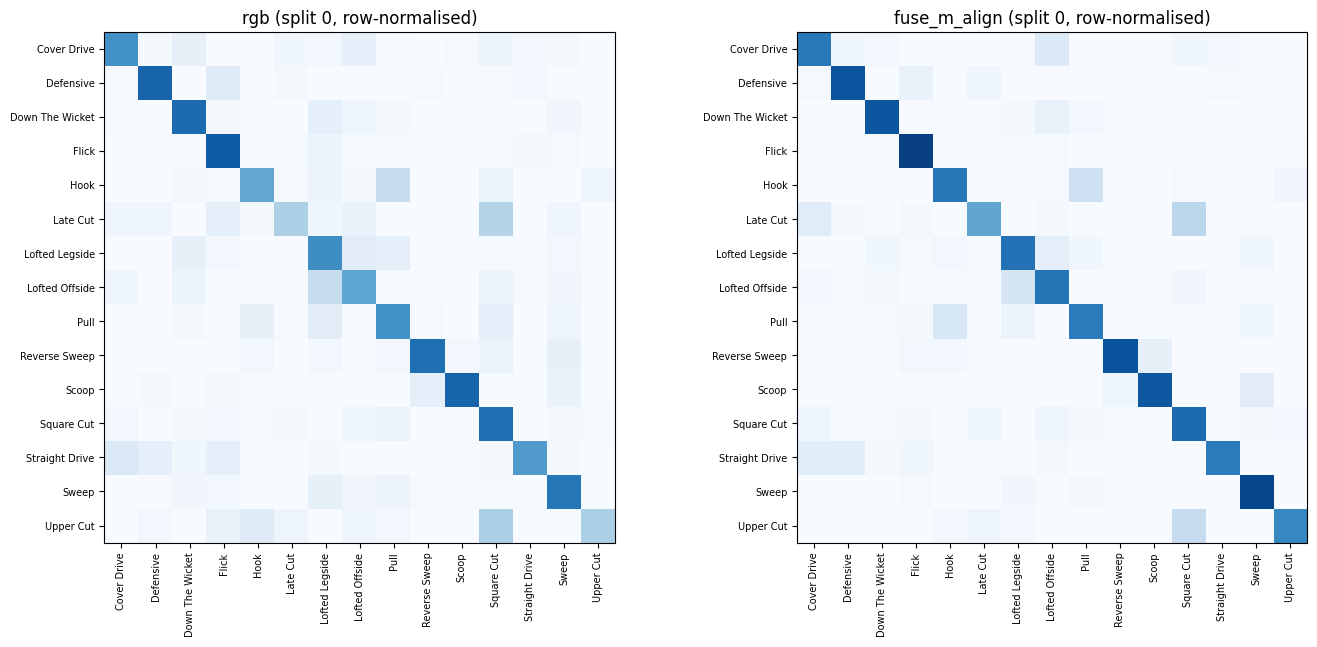

In [8]:
# ===== CELL 1: paste this whole cell, run it (writes the two modules; prints sizes) =====
fe = r'''"""Stage 2: frozen EfficientNetV2-S features from the Stage-1 segmentation-overlay crops.

For every ok clip we keep ONLY the frames where the striker was tracked (the paper also drops striker-less frames)
and store, per frame:  2x2-avg-pooled last feature map (1280*2*2 = 5120, float16) for the crop AND for its
horizontally mirrored copy (needed for mirror augmentation / test-time augmentation), plus the pose / box arrays
compacted to the same frames.
"""
import glob
import os
import pickle
import time

import cv2
import numpy as np

FEAT_DIM = 5120


def find_cache(root="/kaggle/input"):
    """Locate the Stage-1 cache directory (the one with the most chunk_*.pkl files) under `root`."""
    best, bestn = None, 0
    for dp, _, fs in os.walk(root):
        n = sum(f.startswith("chunk_") and f.endswith(".pkl") for f in fs)
        if n > bestn:
            best, bestn = dp, n
    return best, bestn


def compact(rec):
    """Keep only striker-tracked frames."""
    v = np.where(rec["valid"])[0]
    return dict(idx=v.astype(np.int16), kp=rec["kp"][v], kc=rec["kc"][v], sbox=rec["sbox"][v],
                bat=rec["bat"][v], W=rec["W"], H=rec["H"], n_total=rec["n"])


def build_model(device):
    import torch
    import torchvision
    m = torchvision.models.efficientnet_v2_s(weights=torchvision.models.EfficientNet_V2_S_Weights.IMAGENET1K_V1)
    body = m.features.eval().to(device).half()
    for p in body.parameters():
        p.requires_grad_(False)
    mean = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1).half()
    std = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1).half()
    return body, mean, std


def clip_features(jpgs, body, mean, std, device, min_batch=1):
    """jpgs: list of JPEG bytes (BGR overlay crops, 224x224). Returns (f, f_flip) as float16 arrays (n, 5120)."""
    import torch
    import torch.nn.functional as F
    ims = [cv2.cvtColor(cv2.imdecode(np.frombuffer(j, np.uint8), cv2.IMREAD_COLOR), cv2.COLOR_BGR2RGB) for j in jpgs]
    x = torch.from_numpy(np.stack(ims)).to(device).permute(0, 3, 1, 2).half().div_(255)
    x = (x - mean) / std
    x = torch.cat([x, x.flip(3)], 0)  # [originals ; mirrored]
    with torch.no_grad():
        fm = body(x)                                  # (2n, 1280, 7, 7)
        fm = F.adaptive_avg_pool2d(fm, 2).flatten(1)  # (2n, 5120)
    fm = fm.float().cpu().numpy().astype(np.float16)
    n = len(jpgs)
    return fm[:n], fm[n:]


def extract(cache_dir, out_dir, device="cuda", limit_chunks=0, log=print):
    os.makedirs(out_dir, exist_ok=True)
    body, mean, std = build_model(device)
    files = sorted(glob.glob(os.path.join(cache_dir, "chunk_*.pkl")))
    if limit_chunks:
        files = files[:limit_chunks]
    t0, nclips = time.time(), 0
    for fi, f in enumerate(files):
        out = os.path.join(out_dir, "feat_" + os.path.basename(f)[len("chunk_"):])
        if os.path.exists(out):
            continue
        recs = pickle.load(open(f, "rb"))
        res = []
        for r in recs:
            if not r.get("ok"):
                continue
            c = compact(r)
            if len(c["idx"]) < 4:
                continue
            jp = [r["jpg_seg"][i] for i in c["idx"]]
            c["f"], c["ff"] = clip_features(jp, body, mean, std, device)
            c.update(cls=r["cls"], match=r["match"], clip=r["clip"], path=r["path"])
            res.append(c)
            nclips += 1
        tmp = out + ".tmp"
        with open(tmp, "wb") as fh:
            pickle.dump(res, fh, protocol=4)
        os.replace(tmp, out)
        log(f"[{time.strftime('%H:%M:%S')}] {os.path.basename(out)} ({fi + 1}/{len(files)}) | {len(res)}/{len(recs)} clips kept"
            f" | {(time.time() - t0) / max(nclips, 1):.3f}s/clip")
    return nclips


if __name__ == "__main__":
    import argparse
    ap = argparse.ArgumentParser()
    ap.add_argument("--cache", required=True)
    ap.add_argument("--out", required=True)
    ap.add_argument("--limit_chunks", type=int, default=0)
    a = ap.parse_args()
    extract(a.cache, a.out, limit_chunks=a.limit_chunks)
'''
fu = r'''"""Stage 3: pose features, mirroring, phase alignment, match-level splits, RGB / pose / fusion training, evaluation.

Everything that does not need torch is plain numpy (so it can be unit-tested anywhere).
"""
import glob
import json
import os
import pickle
import time
from dataclasses import dataclass

import numpy as np

try:
    import torch
    import torch.nn as nn
    HAVE_TORCH = True
except Exception:  # pragma: no cover
    HAVE_TORCH = False

FEAT_DIM = 5120
K_FRAMES = 15
# COCO-17: 0 nose, 1/2 eyes, 3/4 ears, 5/6 shoulders, 7/8 elbows, 9/10 wrists, 11/12 hips, 13/14 knees, 15/16 ankles
FLIP_PERM = [0, 2, 1, 4, 3, 6, 5, 8, 7, 10, 9, 12, 11, 14, 13, 16, 15]
ANGLE_TRIPLES = [(5, 7, 9), (6, 8, 10), (7, 5, 11), (8, 6, 12), (5, 11, 13), (6, 12, 14), (11, 13, 15), (12, 14, 16)]


# ----------------------------------------------------------------------------- pose features
def flip_pose(kp, kc, W):
    """Mirror a skeleton horizontally: x -> W-x and swap left/right joints."""
    k2 = kp[:, FLIP_PERM].copy()
    k2[..., 0] = W - k2[..., 0]
    return k2, kc[:, FLIP_PERM].copy()


def fill_missing(kp, kc, thr=0.25):
    """Low-confidence joints are replaced by linear interpolation over the (valid-frame) sequence."""
    n = len(kp)
    t = np.arange(n)
    out = kp.astype(np.float32).copy()
    good = kc >= thr
    cen = np.array([kp[i][good[i]].mean(0) if good[i].any() else kp[i].mean(0) for i in range(n)], np.float32)
    for j in range(kp.shape[1]):
        g = good[:, j]
        if g.sum() >= 1:
            for d in range(2):
                out[:, j, d] = np.interp(t, t[g], kp[g, j, d])
        else:
            out[:, j] = cen
    return out


def _angle(a, b, c):
    u, v = a - b, c - b
    cos = (u * v).sum(-1) / (np.linalg.norm(u, axis=-1) * np.linalg.norm(v, axis=-1) + 1e-6)
    return np.arccos(np.clip(cos, -1, 1)) / np.pi


def pose_features(kp, kc, idx):
    """kp (n,17,2) image coords, kc (n,17), idx (n,) original frame numbers.
    Returns feats (n,68) and wrist speed (n,) in torso-lengths / frame.
    68 = 34 hip-centred torso-scaled coords + 17 confidences + 8 joint angles + 1 torso lean
         + 4 wrist velocities + 2 hip velocity + 2 hip displacement from first frame."""
    n = len(kp)
    k = fill_missing(kp, kc)
    hip = (k[:, 11] + k[:, 12]) / 2
    sho = (k[:, 5] + k[:, 6]) / 2
    sc = max(float(np.median(np.linalg.norm(sho - hip, axis=1))), 8.0)  # clip-level torso length in px
    rel = (k - hip[:, None]) / sc
    gap = np.maximum(np.diff(idx.astype(np.float32)), 1.0)

    def vel(x):
        v = np.zeros_like(x)
        if n > 1:
            v[1:] = np.diff(x, axis=0) / gap.reshape((-1,) + (1,) * (x.ndim - 1))
            v[0] = v[1]
        return v

    wv = vel(k[:, [9, 10]] / sc).reshape(n, 4)
    hv = vel(hip / sc)
    hd = (hip - hip[0]) / sc
    ang = np.stack([_angle(k[:, a], k[:, b], k[:, c]) for a, b, c in ANGLE_TRIPLES], 1)
    lean = (np.arctan2(sho[:, 0] - hip[:, 0], -(sho[:, 1] - hip[:, 1])) / np.pi)[:, None]
    feats = np.concatenate([rel.reshape(n, 34), kc, ang, lean, wv, hv, hd], 1).astype(np.float32)
    speed = np.maximum(np.linalg.norm(wv[:, :2], axis=1), np.linalg.norm(wv[:, 2:], axis=1))
    return feats, speed


def peak_index(speed, lo_frac=0.2, hi_frac=0.85):
    """Impact proxy = frame of maximum (smoothed) wrist speed, searched in the middle of the clip."""
    n = len(speed)
    s = np.convolve(np.pad(speed, 1, mode="edge"), [0.25, 0.5, 0.25], mode="valid")
    lo = int(lo_frac * (n - 1))
    hi = max(lo + 1, int(hi_frac * (n - 1)))
    return int(lo + np.argmax(s[lo:hi + 1]))


# ----------------------------------------------------------------------------- temporal sampling
def positions(nv, K=K_FRAMES, peak=None, jitter=False, rng=None, peak_k=8):
    """Indices (into the nv striker-valid frames) of the K frames fed to the network.
    peak=None  -> uniform sampling (paper).  peak=p -> piecewise-linear time warp so frame p lands on slot peak_k."""
    k = np.arange(K, dtype=np.float64)
    if jitter:
        k = np.sort(np.clip(k + rng.uniform(-0.5, 0.5, K), 0, K - 1))
    if peak is None or nv < 3:
        pos = k / (K - 1) * (nv - 1)
    else:
        pos = np.where(k <= peak_k, peak * k / peak_k, peak + (nv - 1 - peak) * (k - peak_k) / (K - 1 - peak_k))
    return np.clip(np.rint(pos).astype(int), 0, nv - 1)


# ----------------------------------------------------------------------------- data
def load_clips(feat_dir, classes=None, limit=0, log=print):
    """Load feature chunks -> list of per-clip dicts with RGB feats (orig+mirror) and pose feats (orig+mirror)."""
    files = sorted(glob.glob(os.path.join(feat_dir, "feat_*.pkl")))
    raw = []
    for f in files:
        raw += pickle.load(open(f, "rb"))
        if limit and len(raw) >= limit:
            raw = raw[:limit]
            break
    if classes is None:
        classes = sorted({r["cls"] for r in raw})
    cid = {c: i for i, c in enumerate(classes)}
    data = []
    for r in raw:
        kp, kc, idx, W = r["kp"], r["kc"], r["idx"], r["W"]
        P, sp = pose_features(kp, kc, idx)
        kpf, kcf = flip_pose(kp, kc, W)
        Pf, _ = pose_features(kpf, kcf, idx)
        data.append(dict(R=r["f"], Rf=r["ff"], P=P, Pf=Pf, nv=len(idx), peak=peak_index(sp),
                         y=cid[r["cls"]], match=int(r["match"]), cls=r["cls"]))
    log(f"loaded {len(data)} clips | {len(classes)} classes | mean valid frames {np.mean([d['nv'] for d in data]):.1f}")
    return data, classes


def make_split(matches, y, n_classes, seed, fr=(0.70, 0.15), tries=400):
    """Match-level split (no match appears in two splits). Among `tries` random match orders keep the one whose
    per-class proportions are closest to the target. Returns split id per clip (0 train / 1 val / 2 test)."""
    matches, y = np.asarray(matches), np.asarray(y)
    um, inv = np.unique(matches, return_inverse=True)
    M = np.zeros((len(um), n_classes))
    np.add.at(M, (inv, y), 1)
    tot = M.sum(0)
    target = np.stack([tot * fr[0], tot * fr[1], tot * (1 - fr[0] - fr[1])])
    rng = np.random.default_rng(seed)
    best, bscore = None, 1e18
    for _ in range(tries):
        perm = rng.permutation(len(um))
        cum = np.cumsum(M.sum(1)[perm]) / M.sum()
        a = np.empty(len(um), int)
        a[perm] = np.where(cum <= fr[0], 0, np.where(cum <= fr[0] + fr[1], 1, 2))
        cnt = np.stack([M[a == s].sum(0) for s in range(3)])
        score = (((cnt - target) / np.maximum(target, 1)) ** 2).sum()
        if score < bscore:
            best, bscore = a.copy(), score
    return best[inv]


# ----------------------------------------------------------------------------- metrics
def confusion(y, p, C):
    cm = np.zeros((C, C), int)
    np.add.at(cm, (y, p), 1)
    return cm


def per_class_f1(cm):
    tp = np.diag(cm).astype(float)
    fp, fn = cm.sum(0) - tp, cm.sum(1) - tp
    return np.where(tp > 0, tp / (tp + 0.5 * (fp + fn) + 1e-12), 0.0)


def metrics(y, probs, C):
    p = probs.argmax(1)
    cm = confusion(y, p, C)
    f1 = per_class_f1(cm)
    sup = cm.sum(1) > 0
    return dict(acc=float((p == y).mean()), f1=float(f1[sup].mean()), per_class=f1.tolist(), cm=cm.tolist())


# ----------------------------------------------------------------------------- batching
@dataclass
class Cfg:
    name: str
    rgb: bool = True
    pose: bool = False
    mirror: bool = False   # random mirroring in training + mirror TTA at evaluation
    align: bool = False    # phase-aligned temporal sampling
    moddrop: float = 0.0   # modality dropout probability (each modality), fusion only
    K: int = K_FRAMES


CFGS = [
    Cfg("rgb"),
    Cfg("rgb_m", mirror=True),
    Cfg("pose_m", rgb=False, pose=True, mirror=True),
    Cfg("pose_m_align", rgb=False, pose=True, mirror=True, align=True),
    Cfg("fuse", pose=True, moddrop=0.15),
    Cfg("fuse_m", pose=True, mirror=True, moddrop=0.15),
    Cfg("fuse_m_align", pose=True, mirror=True, align=True, moddrop=0.15),
]


def make_batch(data, ids, cfg, rng=None, train=False, flip=None):
    """flip=None: random per sample when training with cfg.mirror, else no flip. flip=True/False: forced (TTA)."""
    B, K = len(ids), cfg.K
    D = data[0]["P"].shape[1]
    xr = np.empty((B, K, FEAT_DIM), np.float16) if cfg.rgb else None
    xp = np.empty((B, K, D), np.float32) if cfg.pose else None
    for b, i in enumerate(ids):
        c = data[i]
        fl = bool(flip) if flip is not None else bool(train and cfg.mirror and rng.random() < 0.5)
        pos = positions(c["nv"], K, c["peak"] if cfg.align else None, jitter=train, rng=rng)
        if xr is not None:
            xr[b] = (c["Rf"] if fl else c["R"])[pos]
        if xp is not None:
            xp[b] = (c["Pf"] if fl else c["P"])[pos]
    return xr, xp


# ----------------------------------------------------------------------------- model
if HAVE_TORCH:
    class Net(nn.Module):
        """Paper head (GRU-128 over frames -> flatten -> BN -> Dense-1024 -> softmax) with optional pose branch."""

        def __init__(self, use_rgb, use_pose, dpose=68, K=K_FRAMES, h=128, nc=15, moddrop=0.0):
            super().__init__()
            self.use_rgb, self.use_pose, self.moddrop = use_rgb, use_pose, moddrop
            if use_rgb:
                self.rnorm = nn.LayerNorm(FEAT_DIM)
                self.rdrop = nn.Dropout(0.3)
                self.rgru = nn.GRU(FEAT_DIM, h, batch_first=True)
            if use_pose:
                self.pin = nn.Sequential(nn.Linear(dpose, 128), nn.ReLU(), nn.Dropout(0.2))
                self.pgru = nn.GRU(128, h, batch_first=True)
                self.register_buffer("pm", torch.zeros(dpose))
                self.register_buffer("ps", torch.ones(dpose))
            d = h * K * (int(use_rgb) + int(use_pose))
            self.head = nn.Sequential(nn.BatchNorm1d(d), nn.Linear(d, 1024), nn.ReLU(), nn.Dropout(0.5), nn.Linear(1024, nc))

        def forward(self, xr=None, xp=None):
            zs = []
            if self.use_rgb:
                zs.append(self.rgru(self.rdrop(self.rnorm(xr)))[0])
            if self.use_pose:
                zs.append(self.pgru(self.pin((xp - self.pm) / self.ps))[0])
            if self.training and self.moddrop > 0 and len(zs) == 2:
                u = torch.rand(zs[0].shape[0], 1, 1, device=zs[0].device)
                zs[0] = zs[0] * (u >= self.moddrop).float()                       # RGB dropped when u < p
                zs[1] = zs[1] * ((u < self.moddrop) | (u >= 2 * self.moddrop)).float()  # pose dropped when p <= u < 2p
            return self.head(torch.cat(zs, 2).flatten(1))


def _to_dev(xr, xp, dev):
    r = torch.from_numpy(xr).to(dev).float() if xr is not None else None
    p = torch.from_numpy(xp).to(dev) if xp is not None else None
    return r, p


def predict_probs(model, data, ids, cfg, dev, tta, bs=256):
    model.eval()
    out = []
    with torch.no_grad():
        for s in range(0, len(ids), bs):
            b = ids[s:s + bs]
            pr = 0
            for fl in ([False, True] if tta else [False]):
                xr, xp = make_batch(data, b, cfg, flip=fl)
                r, p = _to_dev(xr, xp, dev)
                pr = pr + torch.softmax(model(r, p), 1)
            out.append((pr / (2 if tta else 1)).cpu().numpy())
    return np.concatenate(out)


def train_run(data, split, C, cfg, seed, epochs=30, bs=64, lr=1e-3, dev="cuda", log=print):
    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)
    y = np.array([d["y"] for d in data])
    tr, va, te = [np.where(split == s)[0] for s in range(3)]
    model = Net(cfg.rgb, cfg.pose, data[0]["P"].shape[1], cfg.K, 128, C, cfg.moddrop).to(dev)
    if cfg.pose:  # z-score pose features with train statistics (orig + mirrored)
        allp = np.concatenate([data[i][k] for i in tr for k in ("P", "Pf")])
        model.pm.copy_(torch.from_numpy(allp.mean(0)))
        model.ps.copy_(torch.from_numpy(np.maximum(allp.std(0), 1e-3)))
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.01)
    steps = epochs * int(np.ceil(len(tr) / bs))
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=steps, pct_start=0.1)
    lossf = nn.CrossEntropyLoss(label_smoothing=0.1)
    best, best_state, best_ep = -1.0, None, -1
    t0 = time.time()
    for ep in range(epochs):
        model.train()
        perm = rng.permutation(tr)
        tl = 0.0
        for s in range(0, len(perm), bs):
            b = perm[s:s + bs]
            if len(b) < 2:
                continue
            xr, xp = make_batch(data, b, cfg, rng=rng, train=True)
            r, p = _to_dev(xr, xp, dev)
            yb = torch.from_numpy(y[b]).to(dev)
            loss = lossf(model(r, p), yb)
            opt.zero_grad(set_to_none=True)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            opt.step()
            sched.step()
            tl += loss.item() * len(b)
        pv = predict_probs(model, data, va, cfg, dev, cfg.mirror)
        f1 = metrics(y[va], pv, C)["f1"]
        if f1 > best:
            best, best_ep = f1, ep
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        if ep % 5 == 0 or ep == epochs - 1:
            log(f"   {cfg.name} s{seed} ep{ep:02d} loss {tl / len(tr):.3f} val-F1 {f1:.4f} (best {best:.4f}@{best_ep}) {time.time() - t0:.0f}s")
    model.load_state_dict(best_state)
    return dict(val_probs=predict_probs(model, data, va, cfg, dev, cfg.mirror), val_y=y[va], val_ids=va,
                test_probs=predict_probs(model, data, te, cfg, dev, cfg.mirror), test_y=y[te], test_ids=te,
                best_ep=best_ep, n_train=len(tr))


def run_experiments(data, classes, out_dir, seeds=(0, 1, 2), cfgs=None, epochs=30, dev="cuda", log=print):
    os.makedirs(out_dir, exist_ok=True)
    cfgs = cfgs or CFGS
    C = len(classes)
    matches = [d["match"] for d in data]
    y = [d["y"] for d in data]
    for seed in seeds:
        split = make_split(matches, y, C, seed)
        cnt = np.stack([np.bincount(np.array(y)[split == s], minlength=C) for s in range(3)])
        log(f"split seed {seed}: clips train/val/test = {[(split == s).sum() for s in range(3)]}, "
            f"min per-class test count {cnt[2].min()}")
        for cfg in cfgs:
            fn = os.path.join(out_dir, f"{cfg.name}_s{seed}.npz")
            if os.path.exists(fn):
                log(f"skip {cfg.name} s{seed} (done)")
                continue
            r = train_run(data, split, C, cfg, seed, epochs, dev=dev, log=log)
            m = metrics(r["test_y"], r["test_probs"], C)
            np.savez(fn + ".tmp.npz", **r)
            os.replace(fn + ".tmp.npz", fn)
            log(f"== {cfg.name} seed {seed}: TEST acc {m['acc']:.4f} macro-F1 {m['f1']:.4f} (best epoch {r['best_ep']})")


# ----------------------------------------------------------------------------- reporting
def late_fusion(a, b):
    """Blend two runs' softmax outputs; weight chosen on validation macro-F1. a, b = loaded npz dicts."""
    C = a["val_probs"].shape[1]
    best, w = -1, 0.5
    for wt in np.linspace(0, 1, 11):
        f = metrics(a["val_y"], wt * a["val_probs"] + (1 - wt) * b["val_probs"], C)["f1"]
        if f > best:
            best, w = f, wt
    return w, w * a["test_probs"] + (1 - w) * b["test_probs"]


def report(out_dir, classes, seeds=(0, 1, 2), cfgs=None, pairs=(("Cover Drive", "Straight Drive"), ("Pull", "Hook")), show=True):
    import pandas as pd
    cfgs = cfgs or CFGS
    C = len(classes)
    res, probs = {}, {}
    for cfg in cfgs:
        for s in seeds:
            fn = os.path.join(out_dir, f"{cfg.name}_s{s}.npz")
            if os.path.exists(fn):
                z = dict(np.load(fn))
                probs[(cfg.name, s)] = z
                res[(cfg.name, s)] = metrics(z["test_y"], z["test_probs"], C)
    # late fusion rows
    for s in seeds:
        if ("rgb_m", s) in probs and ("pose_m", s) in probs:
            a, b = probs[("rgb_m", s)], probs[("pose_m", s)]
            w, pt = late_fusion(a, b)
            res[("late(rgb_m+pose_m)", s)] = metrics(a["test_y"], pt, C)
    names = list(dict.fromkeys(k[0] for k in res))
    rows = []
    for n in names:
        ss = [s for s in seeds if (n, s) in res]
        f1 = np.array([res[(n, s)]["f1"] for s in ss])
        acc = np.array([res[(n, s)]["acc"] for s in ss])
        d = [res[(n, s)]["f1"] - res[("rgb", s)]["f1"] for s in ss if ("rgb", s) in res]
        rows.append(dict(config=n, seeds=len(ss), acc=f"{100 * acc.mean():.2f} ± {100 * acc.std():.2f}",
                         macro_F1=f"{100 * f1.mean():.2f} ± {100 * f1.std():.2f}",
                         dF1_vs_rgb=f"{100 * np.mean(d):+.2f} ± {100 * np.std(d):.2f}" if d else "-"))
    table = pd.DataFrame(rows).set_index("config")
    pc = pd.DataFrame({n: np.mean([res[(n, s)]["per_class"] for s in seeds if (n, s) in res], 0) * 100 for n in names},
                      index=classes).round(1)
    pair_rows = []
    for A, B in pairs:
        if A in classes and B in classes:
            ia, ib = classes.index(A), classes.index(B)
            for n in names:
                e = []
                for s in seeds:
                    if (n, s) in res:
                        cm = np.array(res[(n, s)]["cm"])
                        e.append((cm[ia, ib] + cm[ib, ia]) / max(cm[ia].sum() + cm[ib].sum(), 1))
                pair_rows.append(dict(pair=f"{A} <-> {B}", config=n, confusion_rate_pct=round(100 * np.mean(e), 2)))
    pairs_df = pd.DataFrame(pair_rows)
    if show:
        print(table.to_string())
        print("\nper-class F1 (mean over splits):")
        print(pc.to_string())
        if len(pairs_df):
            print("\nmutual confusion rate:")
            print(pairs_df.pivot(index="config", columns="pair", values="confusion_rate_pct").to_string())
        else:
            print("\n(pair names not found; classes are:", classes, ")")
    return table, pc, pairs_df, res


def plot_confusions(res, classes, names, seed=0):
    import matplotlib.pyplot as plt
    fig, axs = plt.subplots(1, len(names), figsize=(7 * len(names), 6.5))
    axs = np.atleast_1d(axs)
    for ax, n in zip(axs, names):
        cm = np.array(res[(n, seed)]["cm"], float)
        cm = cm / np.maximum(cm.sum(1, keepdims=True), 1)
        ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
        ax.set_xticks(range(len(classes)))
        ax.set_yticks(range(len(classes)))
        ax.set_xticklabels(classes, rotation=90, fontsize=7)
        ax.set_yticklabels(classes, fontsize=7)
        ax.set_title(f"{n} (split {seed}, row-normalised)")
    plt.tight_layout()
    plt.show()
'''
open('/kaggle/working/cricfeat.py','w').write(fe); open('/kaggle/working/cricfuse.py','w').write(fu)
print(len(fe), len(fu), 'bytes written')

# ===== CELL 2: setup + SMOKE TEST (about 3-5 min). Send me the output. =====
import os, sys, glob, time, numpy as np, torch
sys.path.insert(0, '/kaggle/working')
import cricfeat as ce, cricfuse as cf
CACHE = '/kaggle/working/cache'          # Stage-1 output, same session
print(len(glob.glob(CACHE + '/chunk_*.pkl')), 'stage-1 chunks (expect 101)')
DEV = 'cuda'; print(torch.__version__, torch.cuda.get_device_name(0))
FEATS, RUNS = '/kaggle/working/feats', '/kaggle/working/runs'
t0 = time.time()
ce.extract(CACHE, '/kaggle/working/feats_smoke', DEV, limit_chunks=2)
print('feature extraction took', round(time.time() - t0), 's')
sdata, sclasses = cf.load_clips('/kaggle/working/feats_smoke')
t0 = time.time()
cf.run_experiments(sdata, sclasses, '/kaggle/working/runs_smoke', seeds=(0,), epochs=2, dev=DEV)
print('smoke training took', round(time.time() - t0), 's for', len(cf.CFGS), 'configs')
_ = cf.report('/kaggle/working/runs_smoke', sclasses, seeds=(0,))

# ===== CELL 3: FULL RUN (features -> 3 splits x 7 configs -> report). Start it and go to sleep. Resumable: re-run to continue. =====
t0 = time.time()
ce.extract(CACHE, FEATS, DEV)
print('features done in', round((time.time() - t0) / 60, 1), 'min', flush=True)
data, classes = cf.load_clips(FEATS)
t0 = time.time()
cf.run_experiments(data, classes, RUNS, seeds=(0, 1, 2), epochs=30, dev=DEV)
print('experiments took', round((time.time() - t0) / 60, 1), 'min')
table, pc, pairs, res = cf.report(RUNS, classes, seeds=(0, 1, 2))
table.to_csv('/kaggle/working/ablation_table.csv'); pc.to_csv('/kaggle/working/per_class_f1.csv'); pairs.to_csv('/kaggle/working/pair_confusions.csv')
cf.plot_confusions(res, classes, ['rgb', 'fuse_m_align'], seed=0)

                             Accuracy (%) Top-3 acc (%)  Macro-F1 (%) dF1 vs RGB, paired (pts)       ECE (%)
Configuration                                                                                               
RGB (baseline)               67.87 ± 0.86  90.34 ± 0.59  67.18 ± 1.39             +0.00 ± 0.00   4.18 ± 0.53
RGB + mirror                 69.71 ± 2.28  92.73 ± 0.83  68.76 ± 2.18             +1.57 ± 3.55   3.85 ± 0.54
Pose + mirror                77.02 ± 1.33  95.64 ± 0.36  75.93 ± 1.82             +8.75 ± 2.93   7.21 ± 0.73
Pose + mirror + align        77.39 ± 0.85  95.94 ± 0.38  75.94 ± 1.31             +8.76 ± 2.64   7.45 ± 0.28
RGB+Pose                     76.46 ± 0.70  95.03 ± 0.83  75.59 ± 0.59             +8.41 ± 1.98   7.07 ± 0.88
RGB+Pose + mirror            78.72 ± 0.71  96.70 ± 0.78  77.90 ± 0.91            +10.72 ± 2.30   7.37 ± 0.12
RGB+Pose + mirror + align    77.50 ± 1.21  96.25 ± 1.04  76.85 ± 1.42             +9.67 ± 2.81   6.91 ± 0.68
Late fusion (RGB+m,

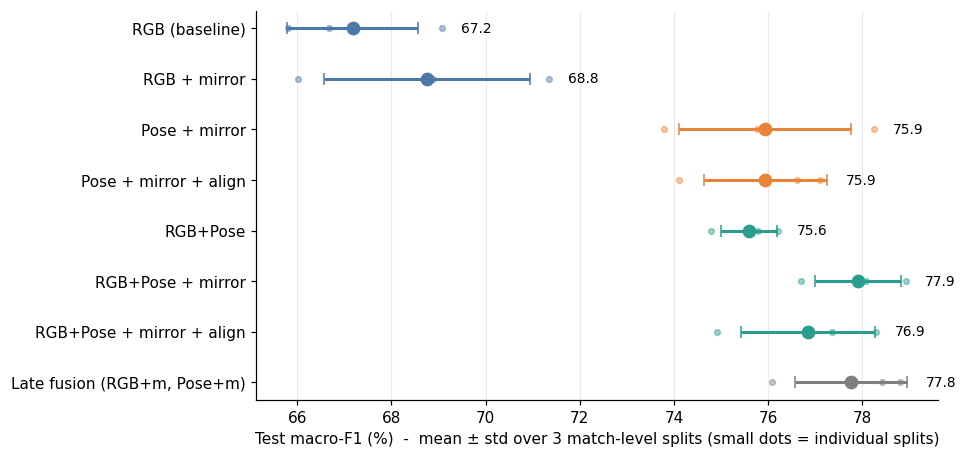

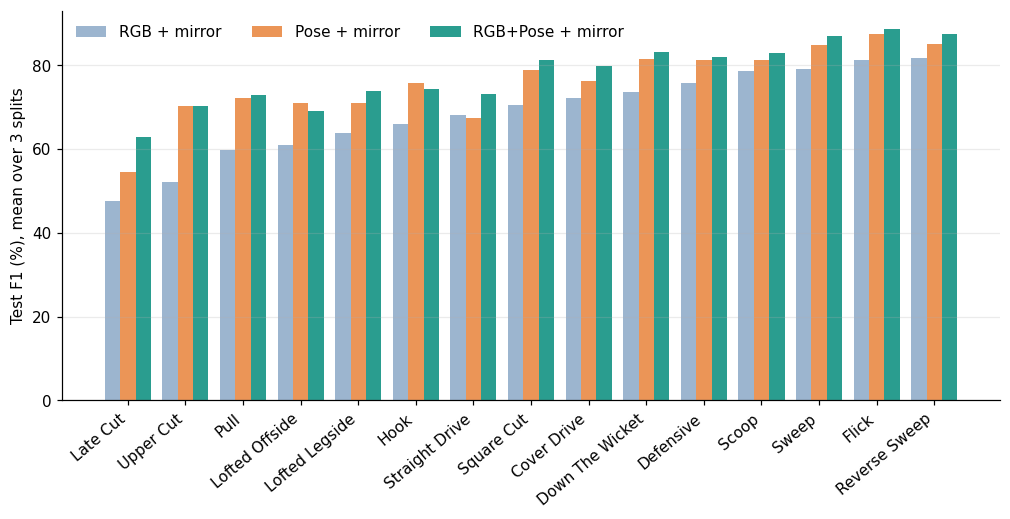

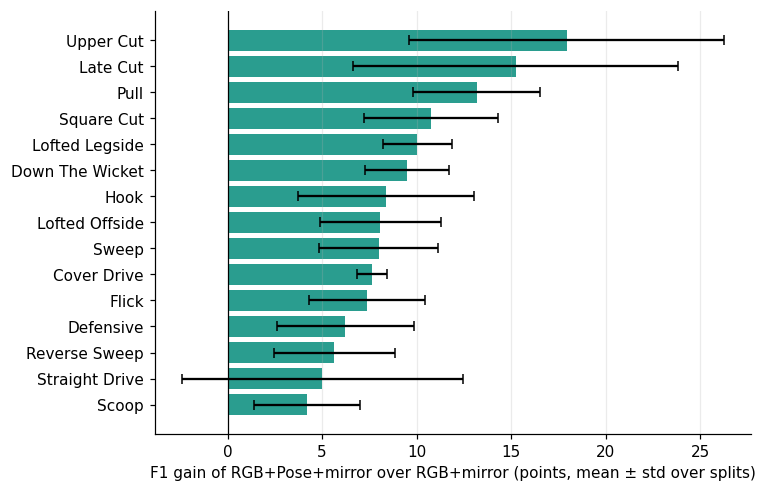

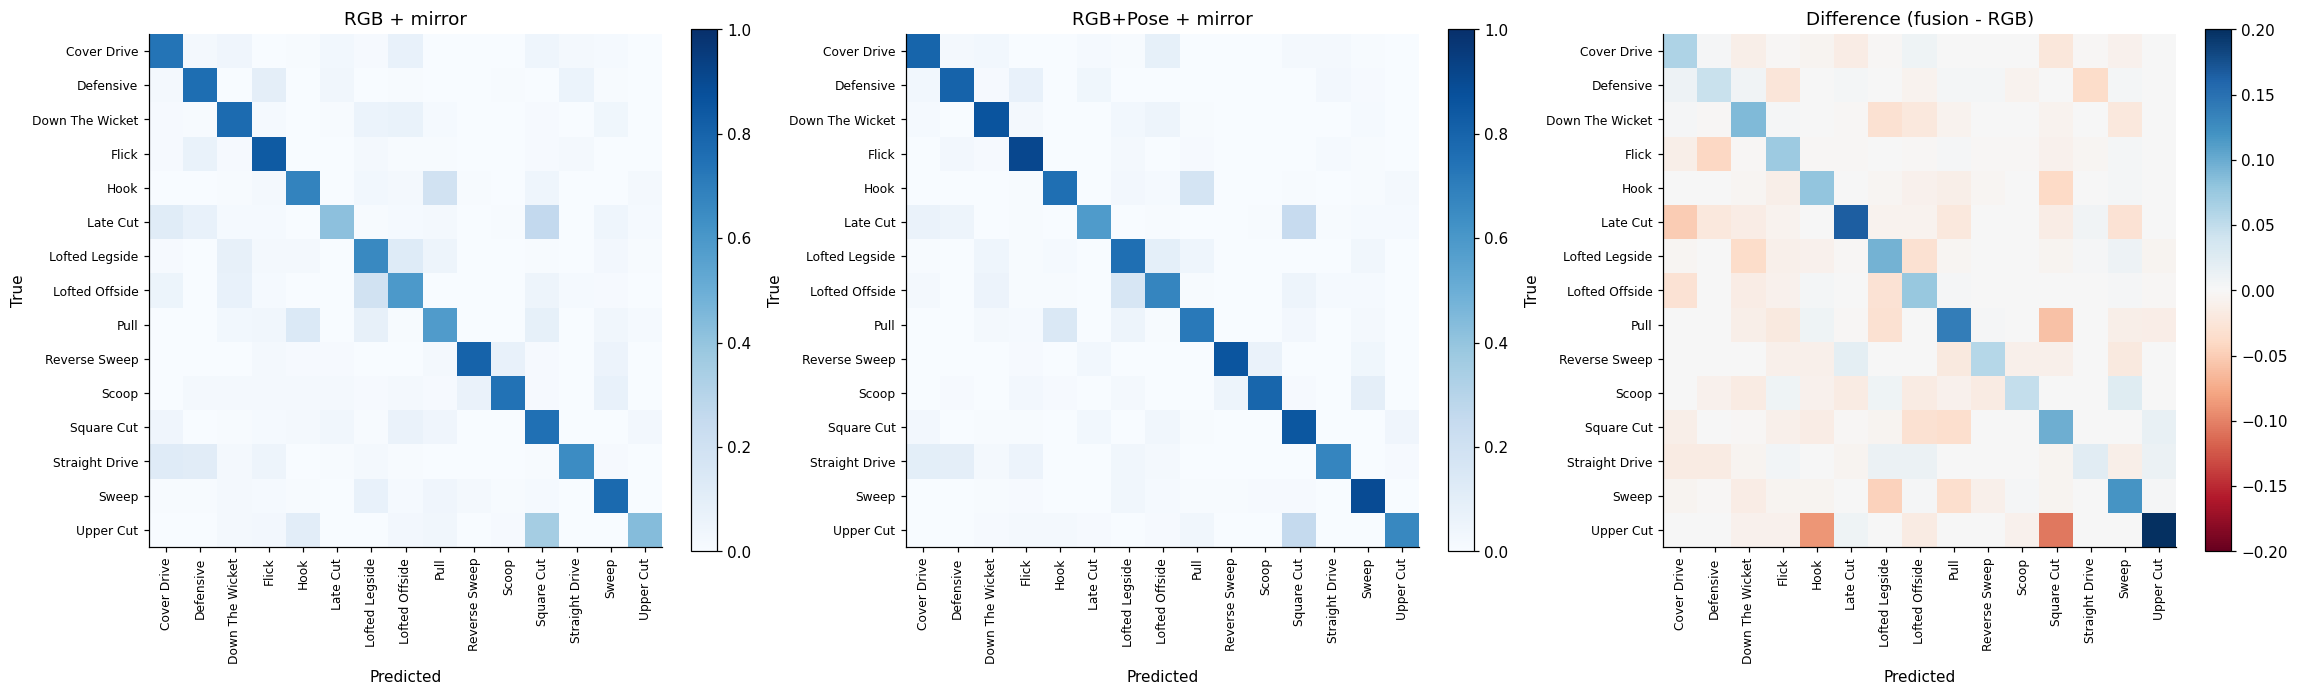

            model           true       predicted  count (3 splits pooled)  rate of true class (%)
     RGB + mirror Lofted Offside  Lofted Legside                       90                    19.0
     RGB + mirror Lofted Legside  Lofted Offside                       61                    12.3
     RGB + mirror           Pull            Hook                       49                    13.8
     RGB + mirror           Hook            Pull                       48                    19.0
     RGB + mirror      Upper Cut      Square Cut                       44                    35.5
     RGB + mirror Lofted Legside Down The Wicket                       40                     8.1
     RGB + mirror       Late Cut      Square Cut                       36                    25.9
     RGB + mirror Lofted Offside Down The Wicket                       34                     7.2
     RGB + mirror          Sweep  Lofted Legside                       32                     7.7
     RGB + mirror   

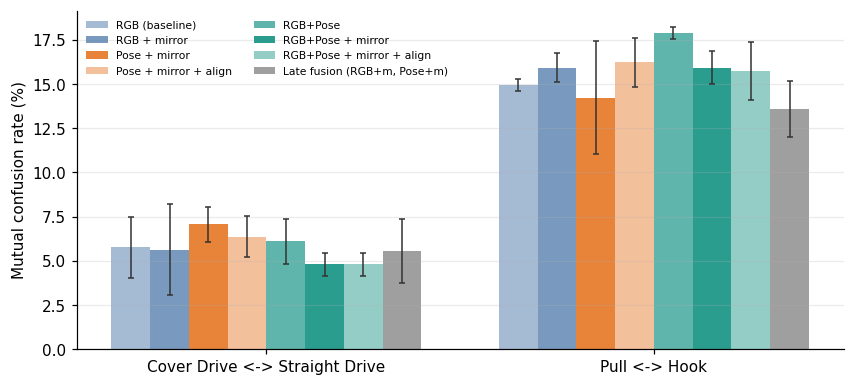

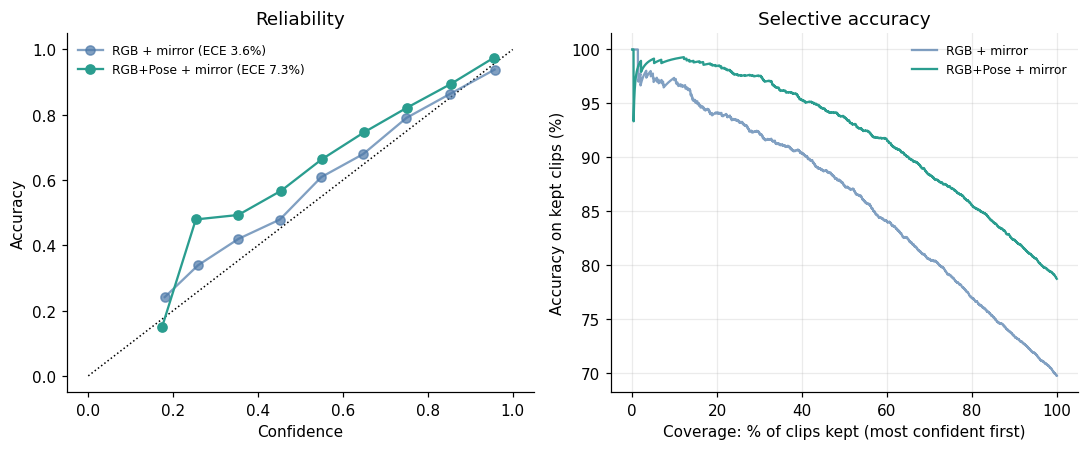

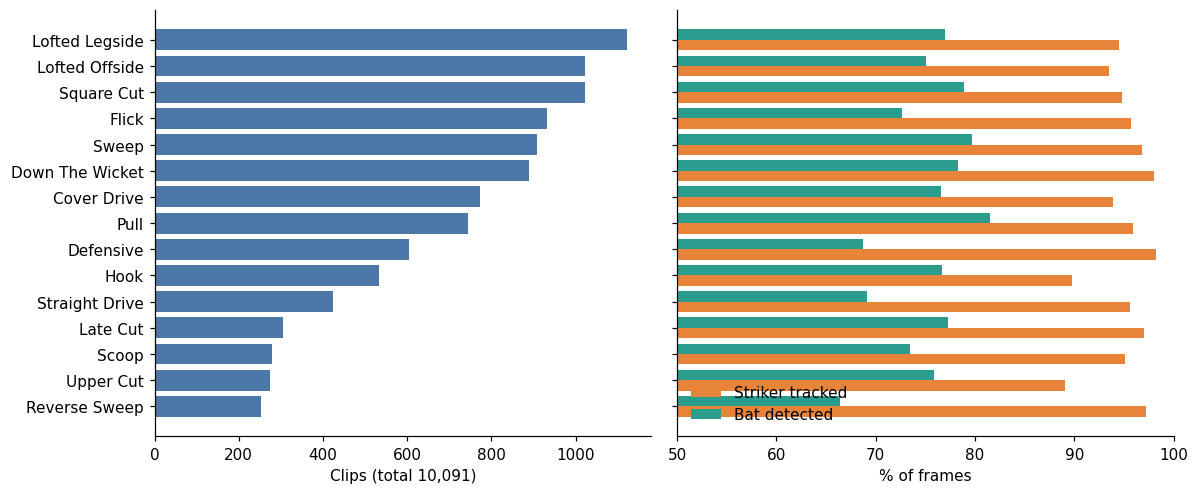

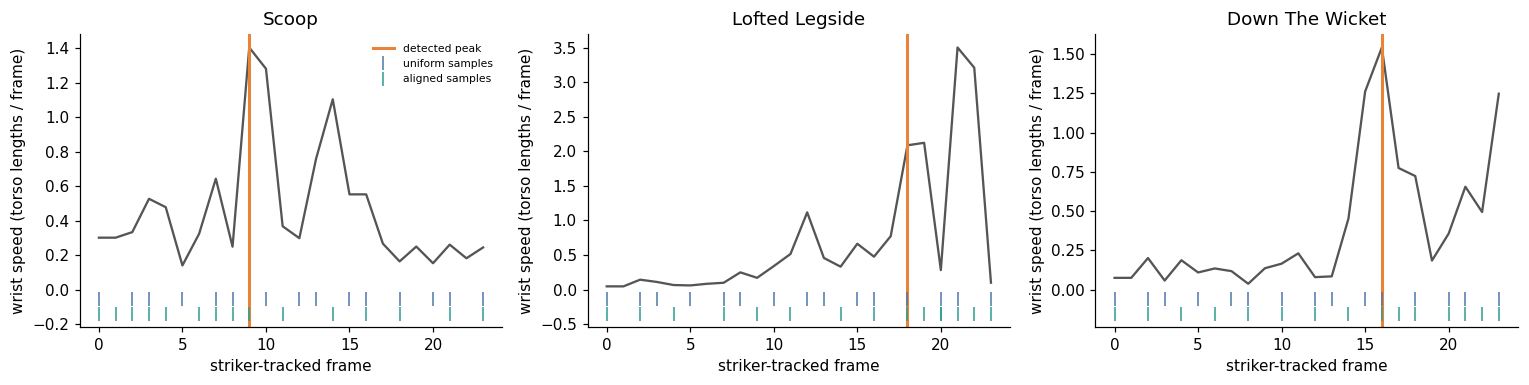

saved to /kaggle/working/figs : ['fig1_ablation.png', 'fig2_per_class_f1.png', 'fig3_per_class_gain.png', 'fig4_confusion.png', 'fig5_pairs.png', 'fig6_calibration.png', 'fig7_dataset.png', 'fig8_phase_alignment.png', 'table_main.csv', 'table_main.tex', 'table_paired.csv', 'table_per_class_f1.csv', 'table_top_confusions.csv']


In [9]:
# ===== Report figures and tables from the saved runs. Needs no training; takes about a minute. =====
import os, sys, glob, numpy as np, pandas as pd, matplotlib.pyplot as plt
sys.path.insert(0, '/kaggle/working')
import cricfuse as cf

RUNS  = globals().get('RUNS', '/kaggle/working/runs')
FIGS  = globals().get('FIGS_DIR', '/kaggle/working/figs')
SEEDS = (0, 1, 2)
os.makedirs(FIGS, exist_ok=True)
CLASSES = ['Cover Drive', 'Defensive', 'Down The Wicket', 'Flick', 'Hook', 'Late Cut', 'Lofted Legside', 'Lofted Offside',
           'Pull', 'Reverse Sweep', 'Scoop', 'Square Cut', 'Straight Drive', 'Sweep', 'Upper Cut']
ORDER = ['rgb', 'rgb_m', 'pose_m', 'pose_m_align', 'fuse', 'fuse_m', 'fuse_m_align', 'late']
LABEL = {'rgb': 'RGB (baseline)', 'rgb_m': 'RGB + mirror', 'pose_m': 'Pose + mirror', 'pose_m_align': 'Pose + mirror + align',
         'fuse': 'RGB+Pose', 'fuse_m': 'RGB+Pose + mirror', 'fuse_m_align': 'RGB+Pose + mirror + align', 'late': 'Late fusion (RGB+m, Pose+m)'}
COL = {'rgb': '#4C78A8', 'rgb_m': '#4C78A8', 'pose_m': '#E8833A', 'pose_m_align': '#E8833A', 'fuse': '#2A9D8F',
       'fuse_m': '#2A9D8F', 'fuse_m_align': '#2A9D8F', 'late': '#7F7F7F'}
plt.rcParams.update({'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False, 'figure.dpi': 110, 'savefig.dpi': 220, 'savefig.bbox': 'tight'})

# ---------- load runs ----------
R = {}
for n in ORDER[:-1]:
    for s in SEEDS:
        fn = f'{RUNS}/{n}_s{s}.npz'
        if os.path.exists(fn): R[(n, s)] = dict(np.load(fn))
for s in SEEDS:
    if ('rgb_m', s) in R and ('pose_m', s) in R:
        w, pt = cf.late_fusion(R[('rgb_m', s)], R[('pose_m', s)])
        R[('late', s)] = dict(test_probs=pt, test_y=R[('rgb_m', s)]['test_y'], best_ep=-1, late_w=w)
names = [n for n in ORDER if any((n, s) in R for s in SEEDS)]
C = next(iter(R.values()))['test_probs'].shape[1]
cls = CLASSES if C == len(CLASSES) else [str(i) for i in range(C)]
seeds_of = {n: [s for s in SEEDS if (n, s) in R] for n in names}
M = {k: cf.metrics(v['test_y'], v['test_probs'], C) for k, v in R.items()}

def top3(p, y): return float(np.mean([yy in np.argsort(pp)[-3:] for pp, yy in zip(p, y)]))
def ece(p, y, bins=10):
    conf, pred = p.max(1), p.argmax(1); ok = (pred == y).astype(float); e = 0.0
    edges = np.linspace(0, 1, bins + 1)
    for a, b in zip(edges[:-1], edges[1:]):
        m = (conf > a) & (conf <= b)
        if m.any(): e += m.mean() * abs(ok[m].mean() - conf[m].mean())
    return float(e)
def ms(v, scale=100): v = np.asarray(v) * scale; return f'{v.mean():.2f} ± {v.std():.2f}'

# ---------- Table 1: main ablation ----------
rows = []
for n in names:
    ss = seeds_of[n]
    d = [100 * (M[(n, s)]['f1'] - M[('rgb', s)]['f1']) for s in ss if ('rgb', s) in M]
    rows.append({'Configuration': LABEL[n], 'Accuracy (%)': ms([M[(n, s)]['acc'] for s in ss]),
                 'Top-3 acc (%)': ms([top3(R[(n, s)]['test_probs'], R[(n, s)]['test_y']) for s in ss]),
                 'Macro-F1 (%)': ms([M[(n, s)]['f1'] for s in ss]),
                 'dF1 vs RGB, paired (pts)': f'{np.mean(d):+.2f} ± {np.std(d):.2f}' if d else '-',
                 'ECE (%)': ms([ece(R[(n, s)]['test_probs'], R[(n, s)]['test_y']) for s in ss])})
T1 = pd.DataFrame(rows).set_index('Configuration'); T1.to_csv(f'{FIGS}/table_main.csv'); print(T1.to_string()); print()
try: open(f'{FIGS}/table_main.tex', 'w').write(T1.to_latex())
except Exception as e: print('latex export skipped:', e)

# ---------- Table 2: per-class F1 ----------
PC = pd.DataFrame({LABEL[n]: np.mean([M[(n, s)]['per_class'] for s in seeds_of[n]], 0) * 100 for n in names}, index=cls).round(1)
PC.to_csv(f'{FIGS}/table_per_class_f1.csv')

# ---------- Table 3: paired comparisons ----------
def paired(a, b):
    ss = [s for s in SEEDS if (a, s) in M and (b, s) in M]
    d = [100 * (M[(a, s)]['f1'] - M[(b, s)]['f1']) for s in ss]
    return dict(A=LABEL[a], B=LABEL[b], mean_diff=round(np.mean(d), 2), std=round(np.std(d), 2), per_split=[round(x, 2) for x in d], positive=f'{sum(x > 0 for x in d)}/{len(d)}')
pairs_cmp = [('rgb_m', 'rgb'), ('pose_m', 'rgb_m'), ('fuse_m', 'rgb_m'), ('fuse_m', 'pose_m'), ('fuse_m', 'fuse'),
             ('pose_m_align', 'pose_m'), ('fuse_m_align', 'fuse_m'), ('fuse_m', 'late')]
T3 = pd.DataFrame([paired(a, b) for a, b in pairs_cmp if a in names and b in names]); T3.to_csv(f'{FIGS}/table_paired.csv', index=False)
print(T3.to_string(index=False)); print()

# ---------- Fig 1: ablation dot plot ----------
fig, ax = plt.subplots(figsize=(8, 4.6)); ys = np.arange(len(names))[::-1]
for y, n in zip(ys, names):
    v = np.array([M[(n, s)]['f1'] for s in seeds_of[n]]) * 100
    ax.errorbar(v.mean(), y, xerr=v.std(), fmt='o', color=COL[n], ms=8, capsize=4, lw=2, zorder=3)
    ax.scatter(v, np.full(len(v), y), s=14, color=COL[n], alpha=.45, zorder=2)
    ax.text(max(v.mean() + v.std(), v.max()) + .4, y, f'{v.mean():.1f}', va='center', fontsize=9)
ax.set_yticks(ys); ax.set_yticklabels([LABEL[n] for n in names]); ax.set_xlabel('Test macro-F1 (%)  -  mean ± std over 3 match-level splits (small dots = individual splits)')
ax.grid(axis='x', alpha=.25); plt.savefig(f'{FIGS}/fig1_ablation.png'); plt.show()

# ---------- Fig 2: per-class F1 (RGB+m vs Pose+m vs Fusion+m) ----------
show = [n for n in ('rgb_m', 'pose_m', 'fuse_m') if n in names]
order = np.argsort(PC[LABEL['rgb_m']].values) if 'rgb_m' in names else np.arange(C)
fig, ax = plt.subplots(figsize=(11, 4.6)); w = .8 / len(show)
for i, n in enumerate(show):
    ax.bar(np.arange(C) + i * w, PC[LABEL[n]].values[order], w, color=COL[n], alpha=[.55, .85, 1][i % 3], label=LABEL[n])
ax.set_xticks(np.arange(C) + w * (len(show) - 1) / 2); ax.set_xticklabels(np.array(cls)[order], rotation=40, ha='right')
ax.set_ylabel('Test F1 (%), mean over 3 splits'); ax.legend(frameon=False, ncol=3, loc='upper left'); ax.grid(axis='y', alpha=.25)
plt.savefig(f'{FIGS}/fig2_per_class_f1.png'); plt.show()

# ---------- Fig 3: per-class gain of fusion over RGB ----------
if 'fuse_m' in names and 'rgb_m' in names:
    ss = [s for s in SEEDS if ('fuse_m', s) in M and ('rgb_m', s) in M]
    D = np.array([np.array(M[('fuse_m', s)]['per_class']) - np.array(M[('rgb_m', s)]['per_class']) for s in ss]) * 100
    o = np.argsort(D.mean(0)); fig, ax = plt.subplots(figsize=(7, 5))
    ax.barh(np.arange(C), D.mean(0)[o], xerr=D.std(0)[o], color=COL['fuse_m'], capsize=3)
    ax.set_yticks(np.arange(C)); ax.set_yticklabels(np.array(cls)[o]); ax.axvline(0, color='k', lw=.8)
    ax.set_xlabel('F1 gain of RGB+Pose+mirror over RGB+mirror (points, mean ± std over splits)'); ax.grid(axis='x', alpha=.25)
    plt.savefig(f'{FIGS}/fig3_per_class_gain.png'); plt.show()

# ---------- Fig 4: pooled confusion matrices ----------
def pooled_cm(n):
    return sum(np.array(M[(n, s)]['cm']) for s in seeds_of[n])
if 'rgb_m' in names and 'fuse_m' in names:
    A, B = pooled_cm('rgb_m'), pooled_cm('fuse_m')
    An, Bn = A / np.maximum(A.sum(1, keepdims=True), 1), B / np.maximum(B.sum(1, keepdims=True), 1)
    fig, axs = plt.subplots(1, 3, figsize=(21, 6.8))
    for ax, mat, t, kw in zip(axs, (An, Bn, Bn - An), ('RGB + mirror', 'RGB+Pose + mirror', 'Difference (fusion - RGB)'),
                              (dict(cmap='Blues', vmin=0, vmax=1), dict(cmap='Blues', vmin=0, vmax=1), dict(cmap='RdBu', vmin=-.2, vmax=.2))):
        im = ax.imshow(mat, **kw); ax.set_title(t); ax.set_xticks(range(C)); ax.set_yticks(range(C))
        ax.set_xticklabels(cls, rotation=90, fontsize=8); ax.set_yticklabels(cls, fontsize=8); ax.set_xlabel('Predicted'); ax.set_ylabel('True')
        plt.colorbar(im, ax=ax, fraction=.046)
    plt.tight_layout(); plt.savefig(f'{FIGS}/fig4_confusion.png'); plt.show()
    # top confused pairs
    tc = []
    for nm, cm in (('RGB + mirror', A), ('RGB+Pose + mirror', B)):
        off = cm.copy(); np.fill_diagonal(off, 0)
        for i, j in zip(*np.unravel_index(np.argsort(off, axis=None)[::-1][:10], off.shape)):
            tc.append({'model': nm, 'true': cls[i], 'predicted': cls[j], 'count (3 splits pooled)': int(off[i, j]), 'rate of true class (%)': round(100 * off[i, j] / cm[i].sum(), 1)})
    pd.DataFrame(tc).to_csv(f'{FIGS}/table_top_confusions.csv', index=False); print(pd.DataFrame(tc).to_string(index=False)); print()

# ---------- Fig 5: confusable pairs ----------
pair_defs = [('Cover Drive', 'Straight Drive'), ('Pull', 'Hook')]
if all(a in cls and b in cls for a, b in pair_defs):
    fig, ax = plt.subplots(figsize=(9, 4)); w = .8 / len(names)
    for k, n in enumerate(names):
        mu, sd = [], []
        for a, b in pair_defs:
            ia, ib = cls.index(a), cls.index(b); v = []
            for s in seeds_of[n]:
                cm = np.array(M[(n, s)]['cm']); v.append(100 * (cm[ia, ib] + cm[ib, ia]) / max(cm[ia].sum() + cm[ib].sum(), 1))
            mu.append(np.mean(v)); sd.append(np.std(v))
        ax.bar(np.arange(2) + k * w, mu, w, yerr=[np.minimum(sd, mu), sd], capsize=2, error_kw=dict(lw=1, ecolor='#333'), color=COL[n], alpha=.5 + .5 * (k % 3) / 2, label=LABEL[n])
    ax.set_xticks(np.arange(2) + w * (len(names) - 1) / 2); ax.set_xticklabels([f'{a} <-> {b}' for a, b in pair_defs])
    ax.set_ylabel('Mutual confusion rate (%)'); ax.legend(frameon=False, fontsize=7, ncol=2); ax.grid(axis='y', alpha=.25)
    plt.savefig(f'{FIGS}/fig5_pairs.png'); plt.show()

# ---------- Fig 6: reliability + selective-accuracy curves ----------
fig, axs = plt.subplots(1, 2, figsize=(10, 4.2)); axs[0].plot([0, 1], [0, 1], 'k:', lw=1)
for n in [x for x in ('rgb_m', 'fuse_m') if x in names]:
    p = np.concatenate([R[(n, s)]['test_probs'] for s in seeds_of[n]]); y = np.concatenate([R[(n, s)]['test_y'] for s in seeds_of[n]])
    conf, ok = p.max(1), (p.argmax(1) == y); edges = np.linspace(0, 1, 11); xs, accs = [], []
    for a, b in zip(edges[:-1], edges[1:]):
        m = (conf > a) & (conf <= b)
        if m.sum() >= 10: xs.append(conf[m].mean()); accs.append(ok[m].mean())
    axs[0].plot(xs, accs, 'o-', color=COL[n], alpha=.7 if n == 'rgb_m' else 1, label=f'{LABEL[n]} (ECE {100 * ece(p, y):.1f}%)')
    o = np.argsort(-conf); cum = np.cumsum(ok[o]) / np.arange(1, len(o) + 1); axs[1].plot(np.arange(1, len(o) + 1) / len(o) * 100, cum * 100, color=COL[n], alpha=.7 if n == 'rgb_m' else 1, label=LABEL[n])
axs[0].set_xlabel('Confidence'); axs[0].set_ylabel('Accuracy'); axs[0].legend(frameon=False, fontsize=8); axs[0].set_title('Reliability')
axs[1].set_xlabel('Coverage: % of clips kept (most confident first)'); axs[1].set_ylabel('Accuracy on kept clips (%)'); axs[1].legend(frameon=False, fontsize=8); axs[1].set_title('Selective accuracy'); axs[1].grid(alpha=.25)
plt.tight_layout(); plt.savefig(f'{FIGS}/fig6_calibration.png'); plt.show()

# ---------- Fig 7: dataset and preprocessing quality (numbers from the Stage-1 summary) ----------
counts = [772, 605, 890, 933, 534, 306, 1123, 1023, 745, 252, 279, 1023, 423, 908, 275]
striker = [93.9, 98.2, 98.0, 95.7, 89.8, 97.0, 94.5, 93.5, 95.9, 97.2, 95.1, 94.8, 95.6, 96.8, 89.1]
bat = [76.6, 68.7, 78.3, 72.6, 76.7, 77.3, 77.0, 75.1, 81.5, 66.4, 73.5, 78.9, 69.1, 79.7, 75.9]
if C == 15:
    o = np.argsort(counts); fig, axs = plt.subplots(1, 2, figsize=(11, 4.6))
    axs[0].barh(np.arange(C), np.array(counts)[o], color='#4C78A8'); axs[0].set_yticks(range(C)); axs[0].set_yticklabels(np.array(cls)[o]); axs[0].set_xlabel('Clips (total 10,091)')
    axs[1].barh(np.arange(C) - .2, np.array(striker)[o], .4, color='#E8833A', label='Striker tracked'); axs[1].barh(np.arange(C) + .2, np.array(bat)[o], .4, color='#2A9D8F', label='Bat detected')
    axs[1].set_yticks(range(C)); axs[1].set_yticklabels([]); axs[1].set_xlim(50, 100); axs[1].set_xlabel('% of frames'); axs[1].legend(frameon=False, loc='lower left')
    plt.tight_layout(); plt.savefig(f'{FIGS}/fig7_dataset.png'); plt.show()

# ---------- Fig 8: phase alignment illustration (needs `data` from the experiment cell) ----------
if 'data' in globals():
    rng = np.random.default_rng(1); ids = rng.choice(len(data), 3, replace=False); fig, axs = plt.subplots(1, 3, figsize=(14, 3.6), sharey=False)
    for ax, i in zip(axs, ids):
        d = data[i]; P = d['P']; sp = np.maximum(np.linalg.norm(P[:, 60:62], axis=1), np.linalg.norm(P[:, 62:64], axis=1))
        ax.plot(sp, color='#555'); ax.axvline(d['peak'], color='#E8833A', lw=2, label='detected peak')
        u = cf.positions(d['nv']); a = cf.positions(d['nv'], peak=d['peak'])
        ax.plot(u, np.full(len(u), -.04 * sp.max()), '|', color='#4C78A8', ms=9, label='uniform samples'); ax.plot(a, np.full(len(a), -.10 * sp.max()), '|', color='#2A9D8F', ms=9, label='aligned samples')
        ax.set_title(d['cls']); ax.set_xlabel('striker-tracked frame'); ax.set_ylabel('wrist speed (torso lengths / frame)')
    axs[0].legend(frameon=False, fontsize=7); plt.tight_layout(); plt.savefig(f'{FIGS}/fig8_phase_alignment.png'); plt.show()

print('saved to', FIGS, ':', sorted(os.listdir(FIGS)))